# Historico de Bitácoras Onomásticas del SEMEFO-DF
# Análisis de datos

Las [Historico de Bitácoras Onomásticas del Servicio Médico Forense del Distrito Federal (SEMEFO-DF)](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai), han sido sistematizada por la Comisión Nacional de Búsqueda (CNB). Este conjunto de datos se obtuvo a través de una solicitud de acceso a la información disponible en el Portal de Transparencia del Instituto Nacional de acceso a la Información (INAI) en noviembre de 2023 y existe una copia en el portal ciudadano _datamx_ de Codeando México.

El **SEMEFO-DF (Servicio Médico Forense Distrito Federal)** ahora [INCIFO-CdMx](https://www.incifocdmx.gob.mx/) es una institución oficial encargada de realizar autopsias y estudios forenses para esclarecer las causas de muerte, principalmente en casos de muertes violentas, sospechosas o relacionadas con hechos delictivos. Las **Bitácoras Onomásticas (BO)** son registros administrativos históricos utilizados por el SEMEFO para documentar el ingreso de cadáveres o restos humanos a sus instalaciones. Estas bitácoras contienen información detallada sobre cada ingreso, como el nombre de la persona fallecida, su edad, sexo, fecha de ingreso, institución de procedencia y diagnóstico preliminar de causa de muerte. En muchos casos, estos registros incluyen datos clave para identificar patrones históricos de mortalidad, enfermedades comunes y factores de riesgo, lo que las convierte en una fuente valiosa para estudios demográficos, epidemiológicos y de salud pública.

Podemos acceder a esta información con la [Plataforma de Transparencia](https://www.plataformadetransparencia.org.mx/Inicio) o en [datamx](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai).

In [1]:
import pandas as pd
from numpy import nan
from helper_pandas import *

import matplotlib.pyplot as plt
import seaborn as sns


from joblib import load

in_file = "data_clean/HBO_clean.pkl"
with open(in_file, 'rb') as f:
     df = load(f)

#Quitar filas vacias
df = df[df['Conocido_desconocido']!='S-D']
df.tail()

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Diagnostico_clasificacion,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1982_07489,S-D,placenta,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,NaN,15a,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,960,3079,semefo_df_bo_1982,156,NaN
BO_1982_07490,S-D,5 dedos del pie derecho de desconocido,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,NaN,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,950,3060,semefo_df_bo_1982,156,NaN
BO_1982_07491,S-D,dedo de desconocido,NaN,NaN,NaN,1982-11-19,1982-11-19,1982.0,11.0,46,...,NaN,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,2005,6389,semefo_df_bo_1982,156,NaN
BO_1982_07492,S-D,4 dedos de desconocido,NaN,NaN,NaN,1982-11-28,1982-11-28,1982.0,11.0,47,...,NaN,27a,XO-2,Coord Territorial 2 Xochimilco (Barrio de San ...,Xochimilco,959,6528,semefo_df_bo_1982,156,NaN
BO_1982_07493,S-D,osamenta de desconocido,NaN,NaN,NaN,1982-10-11,1982-10-11,1982.0,10.0,41,...,NaN,9a,MH-1,Coord Territorial 1 Miguel Hidalgo – Hospital ...,Miguel Hidalgo,4193,5629,semefo_df_bo_1982,156,no se recibio necropsia. es una osamenta.


### Código de color


1. <span style="background:#0504aa">---</span> Poblacion
2. <span style="background:#999999">---</span> S-D  <span style="background:#d9d9d9">---</span> S-D (DF)
3. <span style="background:#377eb8">---</span> Masculino  <span style="background:#80b1d3">---</span> Masculino (DF)
4. <span style="background:#984ea3">---</span> Femenino  <span style="background:#bebada">---</span> Femenino (DF)
5. <span style="background:#4daf4a">---</span> Conocido
6. <span style="background:#dbb40c">---</span> Desconocido
7. <span style="background:#04d8b2">---</span> Cadáver conocido
8. <span style="background:#fdff52">---</span> Cadáver desconocido
9. <span style="background:#c875c4">---</span> Recién nacido
10. <span style="background:#ff7f00">---</span> Feto
11. <span style="background:#f781bf">---</span> Miembros
12. <span style="background:#c85a53">---</span> Restos óseos 


In [2]:
from matplotlib.colors import LinearSegmentedColormap

dic_color = {'Poblacion':'#0504aa', 'S-D':'#999999', 'S-D (DF)':'#d9d9d9', 'Masculino':'#377eb8', 'Masculino (DF)':'#80b1d3', 
             'Femenino':'#984ea3', 'Femenino (DF)':'#bebada', 
             'Conocido':'#4daf4a', 'Desconocido':'#dbb40c', 
             'Cadáver conocido':'#04d8b2', 'Cadáver desconocido':'#fdff52', 
             'Recién nacido':'#c875c4', 
             'Feto':'#ff7f00', 
             'Miembros':'#f781bf', 
             'Restos óseos':'#c85a53', }

gray_to_green = LinearSegmentedColormap.from_list('gray_to_green', ['#d9d9d9', '#2a7e19'])


## Datos faltantes

### Datos faltantes por columna transcrita

In [3]:
col_trans = [c for c in df.columns if 'transcrito' in c]
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan = (df[col_trans]!='S-D')
df_notnan.sum()

Numero_progresivo_transcrito    27152
Nombre_completo_transcrito      96819
Fecha_transcrito                96611
Edad_transcrito                 40183
Diagnostico_transcrito          40966
Procedencia_transcrito          71064
Numero_acta_transcrito          71102
Expediente_SEMEFO_transcrito    96277
Foja_transcrito                 88845
dtype: int64

**Datos faltantes por año**

No todos los años se capturaron todas las variables.

* Edad y Diagnóstico solo fueron capturadas de 1974-1979
* Numero progresivo solo fue capturada de 1974 a 1978 y fue de manera irregular
* Procedencia y acta fueron capturadas de manera irregular de 1968 a 1963
* Foja no fue capturada en 1980

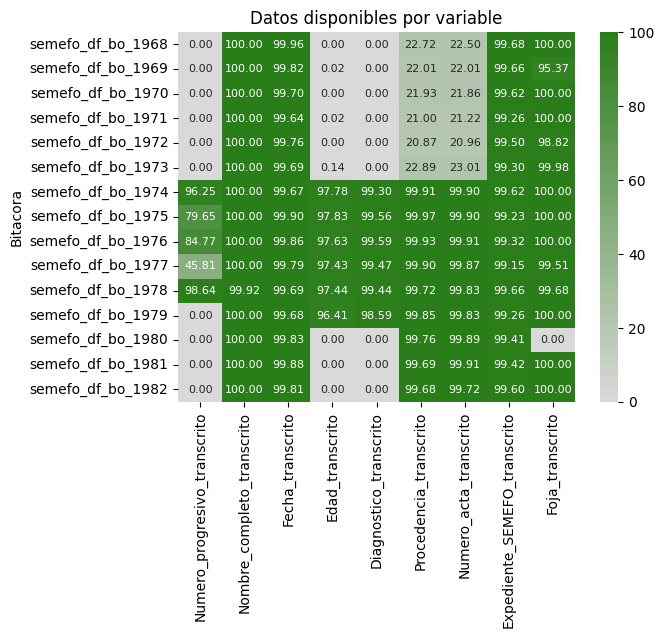

In [4]:
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan['Bitacora'] = df['Bitacora_ingresos']
df_notnan_anual = df_notnan.groupby('Bitacora').sum().divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por variable")
plt.show()

Ignorando las variables que no fueron capturadas en el año

/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.7/site-packages/ipykernel_launcher.py:10: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  # Remove the CWD from sys.path while we load stuff.


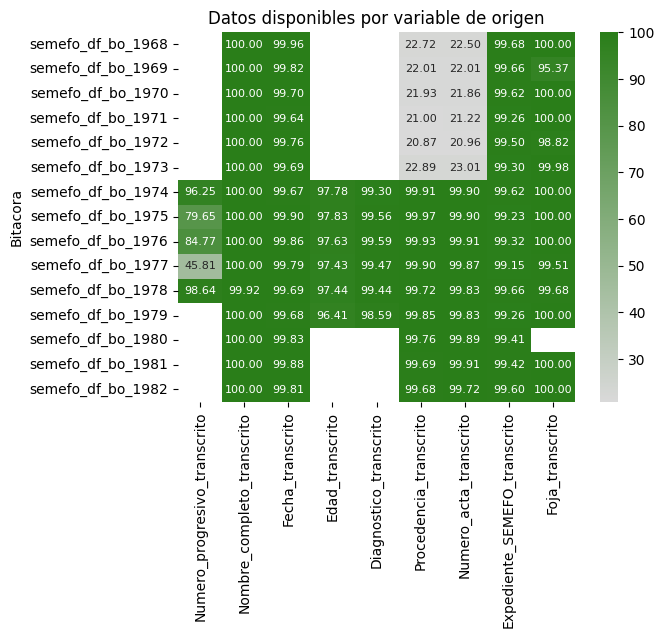

In [5]:
dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    df_notnan.loc[ df_notnan['Bitacora'].isin([f"semefo_df_bo_{a}" for a in años]), col] = nan
df_notnan

df_notnan_anual = df_notnan.groupby('Bitacora', dropna=False) \
                            .apply(lambda x: x.sum(skipna=False)) \
                            .divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por variable de origen")
plt.show()

Correlación entre faltantes
* Existe una correlación alta  (0.996) entre la falta de procedencia y de acta.
* Existe una correlación debil entre la falta del nombre con la fecha (0.253) y el exp semefo (0.162)


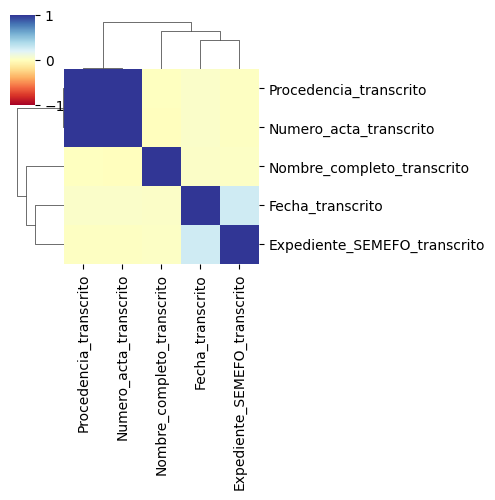

In [6]:
sns.clustermap(df_notnan.corr(), vmin=-1, vmax=1, cmap='RdYlBu', figsize=(5,5))
plt.show()

### Filas con más datos faltantes

* Casos donde hay número progresivo o foja pero ningun dato
* Casos donde solo hay nombre, muchas veces solo apellido
* Casos sin fecha pero con expediente

En general no parece haber un patrón, la cantidad de datos esta fuertemente asociada a que campos se capturaron ese año

In [7]:
df_notnan = (df[col_trans]!='S-D')
df_notnan['Bitacora'] = df['Bitacora_ingresos']

dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    años = [f"semefo_df_bo_{a}" for a in años]
    df_notnan.loc[ df_notnan['Bitacora'].isin(años), col] = nan

df_notnan_row = df_notnan.drop('Bitacora', axis=1).sum(axis=1).to_frame()
df_notnan_row.value_counts().sort_index()

1.0        6
2.0       58
3.0      459
4.0    25153
5.0     7900
6.0    22190
7.0      615
8.0    14044
9.0    26400
dtype: int64

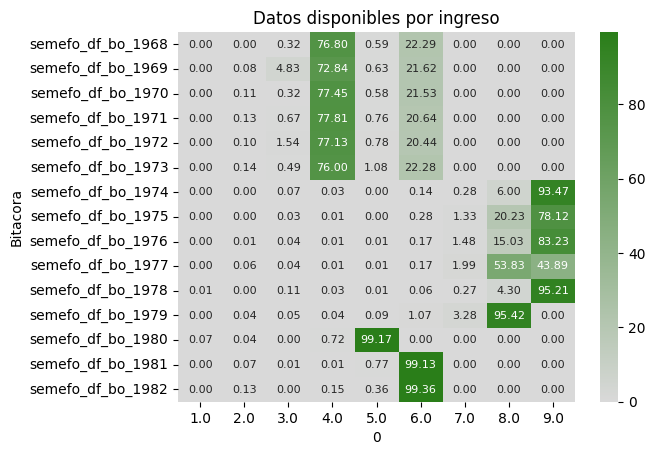

In [8]:
df_notnan_row['Bitacora'] = df['Bitacora_ingresos']
df_notnan_row_anual = df_notnan_row.pivot_table(columns=0, index='Bitacora', aggfunc='size')
df_notnan_row_anual = df_notnan_row_anual.divide(ingresos_anuales, axis=0)
sns.heatmap(df_notnan_row_anual*100, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por ingreso")
plt.show()

### Faltantes por tipo de restos

* De 1968 a 1973 faltan procedencia/acta para cadáveres conocidos
* De 1974 a 1979 faltan edades para miembros
* No todos los años hay restos oseos


Cadáver conocido


/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.7/site-packages/ipykernel_launcher.py:7: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  import sys


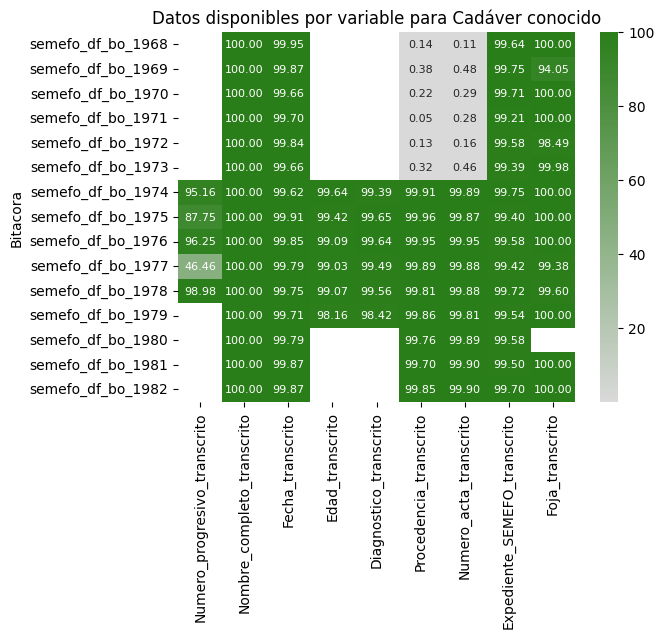

Cadáver desconocido


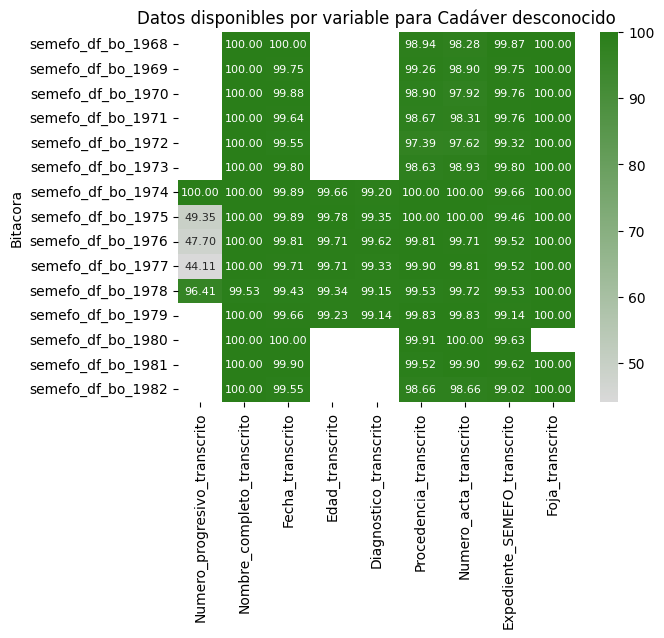

Miembros


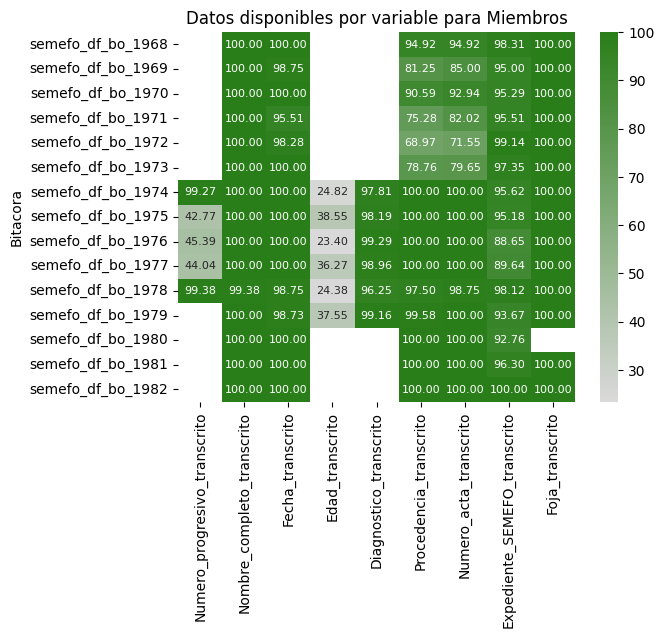

Feto


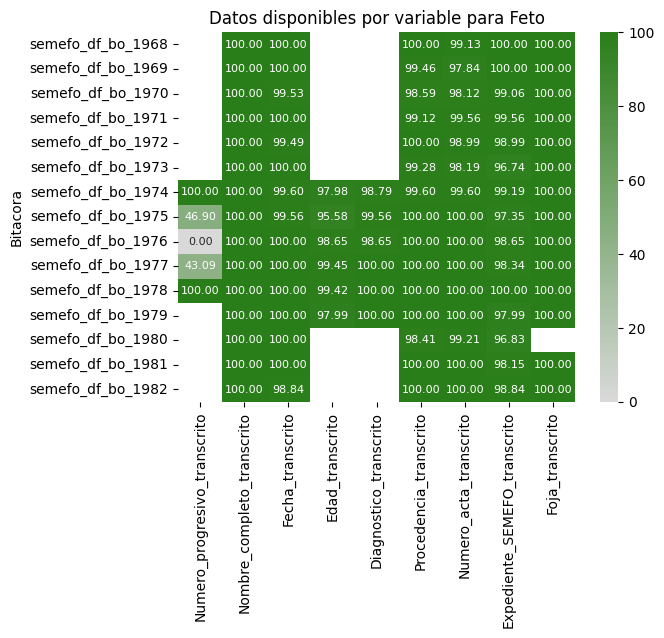

Restos óseos


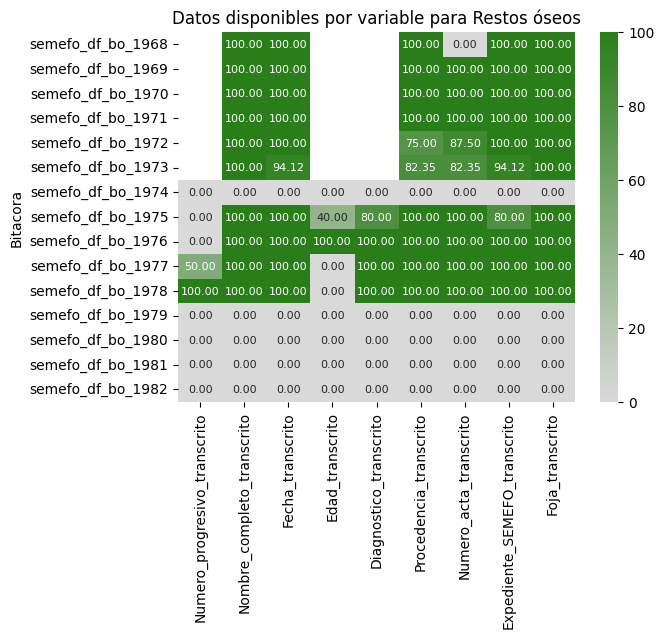

Recién nacido


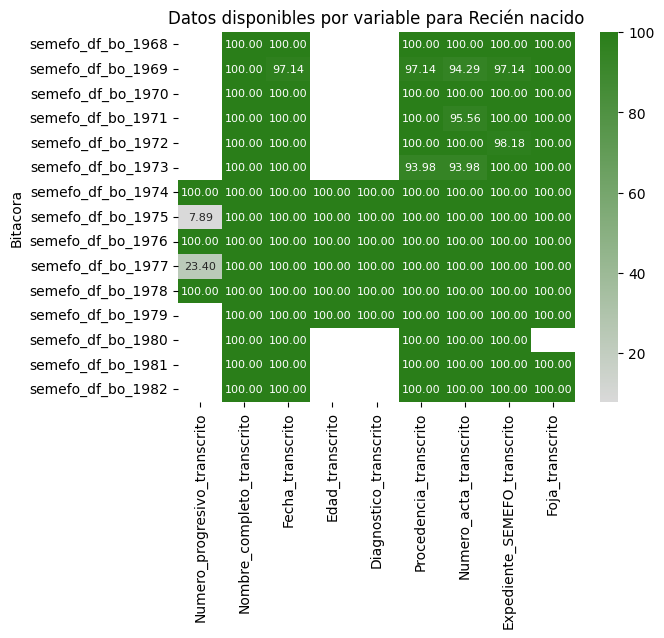

In [9]:
for tipo in df['Tipo_restos'].unique():
    print(tipo)
    ingresos_anuales_tipo = df.loc[df['Tipo_restos']==tipo,'Bitacora_ingresos'].value_counts().sort_index()
    ingresos_anuales_tipo = ingresos_anuales_tipo.replace({0:1.0})
    data = df_notnan[df['Tipo_restos']==tipo]
    data_anual = data.groupby('Bitacora', dropna=False) \
                     .apply(lambda x: x.sum(skipna=False)) \
                     .div( ingresos_anuales_tipo, axis=0 )
    for col in data_anual.columns:
        data_anual[col] = pd.to_numeric(data_anual[col]*100)
    sns.heatmap(data_anual, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
    plt.title(f"Datos disponibles por variable para {tipo}")
    plt.show()

## Resumen estadístico

**Tipo_restos**

In [10]:
categorical_to_freq_and_percentage(df['Tipo_restos']).to_frame().transpose()

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,76756 (79.273%),14479 (14.954%),633 (0.654%),2844 (2.937%),2065 (2.133%),48 (0.05%)


**Nombre**

In [11]:
string_summary(df['Nombre_completo_transcrito'], df['Tipo_restos'], 
               dropna=False, top_n=5,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,hernandez hernandez jesus 7 (0.007%),desconocido 12820 (13.24%),r. nacido 224 (0.231%),feto 2609 (2.695%),nombre confidencial 1880 (1.942%),osamenta 30 (0.031%)
1,lopez lopez mario 6 (0.006%),desconocida 1291 (1.333%),recien nacido 105 (0.108%),nombre confidencial 202 (0.209%),restos humanos 26 (0.027%),restos oseos 8 (0.008%)
2,garcia garcia juan 6 (0.006%),S-D 5 (0.005%),r. nacida 96 (0.099%),fetos 6 (0.006%),placenta 11 (0.011%),desconocido 3 (0.003%)
3,hernandez hernandez antonio 6 (0.006%),desconocido o guadalupe 4 (0.004%),nombre confidencial 72 (0.074%),desconocido (feto) 4 (0.004%),m.i. de: 8 (0.008%),huesos humanos 2 (0.002%)
4,lopez hernandez jose 5 (0.005%),"desconocido o pedro ""n"" 4 (0.004%)",recien nacida 61 (0.063%),feto (2 fetos) con una orden 2 (0.002%),miembro inferior 7 (0.007%),craneo 2 (0.002%)
5,Otro* 76726 (79.242%),Otro* 355 (0.367%),Otro* 75 (0.077%),Otro* 21 (0.022%),Otro* 133 (0.137%),Otro* 3 (0.003%)


''

**Conocido_desconocido**

In [12]:
categorical_summary(df['Conocido_desconocido'], df['Tipo_restos'], percen_round=3, as_str=True)


,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,Total
Conocido,76756 (79.273%),0 (0.0%),31 (0.032%),31 (0.032%),1795 (1.854%),0 (0.0%),78613 (81.191%)
Desconocido,0 (0.0%),14479 (14.954%),602 (0.622%),2813 (2.905%),270 (0.279%),48 (0.05%),18212 (18.809%)
S-D,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


**Sexo**

In [13]:
categorical_summary(df['Sexo'], df['Tipo_restos'], percen_round=3, as_str=True)


,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,Total
Femenino,17923 (18.511%),1580 (1.632%),251 (0.259%),462 (0.477%),384 (0.397%),1 (0.001%),20601 (21.277%)
Masculino,58337 (60.25%),12845 (13.266%),379 (0.391%),662 (0.684%),1511 (1.561%),7 (0.007%),73741 (76.159%)
S-D,496 (0.512%),54 (0.056%),3 (0.003%),1720 (1.776%),170 (0.176%),40 (0.041%),2483 (2.564%)


**Edad**

In [14]:
numeric_summary(df['Edad_estandar'],df['Tipo_restos'],percen_round=3)

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,All
count,32348,6094,223,1174,329,3,40171
mean,35.845,40.058,0,0,35.587,26,35.235
std,22.084,17.539,0,0,19.799,12.49,22.127
min,0,0,0,0,0,16,0
25%,20,28,0,0,20,19,20
50%,33,40,0,0,30,22,34
75%,52,50,0,0,48,31,50
max,108,90,0,0,91,40,108


**Diagnostico**

In [15]:
string_summary(df['Diagnostico_extendido'], df['Tipo_restos'], 
               dropna=False, top_n=6,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,Sin datos* 44782 (46.25%),Sin datos* 8499 (8.778%),Sin datos* 423 (0.437%),Sin datos* 1687 (1.742%),Sin datos* 1102 (1.138%),Sin datos* 40 (0.041%)
1,traumatismo multiple 6112 (6.312%),traumatismo multiple 1428 (1.475%),asfixia neo natorum 75 (0.077%),expulsion prematura del seno materno 543 (0.561%),amputacion quirurgica por traumatismo 608 (0.628%),indeterminado 3 (0.003%)
2,traumatismo craneo encefalico 5234 (5.406%),traumatismo craneo encefalico 782 (0.808%),bronconeumonia 32 (0.033%),asfixia neo natorum 461 (0.476%),gangrena 49 (0.051%),traumatismo craneo encefalico 2 (0.002%)
3,bronconeumonia 1272 (1.314%),bronconeumonia 699 (0.722%),asfixia por estrangulacion 16 (0.017%),indeterminado 36 (0.037%),traumatismo miembro 33 (0.034%),no copias 1 (0.001%)
4,congestion visceral generalizada 1153 (1.191%),bronconeumonia + cirrosis hepatica 427 (0.441%),traumatismo craneo encefalico 13 (0.013%),falta cuidado post natales 18 (0.019%),amputacion quirurgica por traumatismo + gangrena 30 (0.031%),traumatismo cervico 1 (0.001%)
5,traumatismo craneo torax 1033 (1.067%),congestion visceral generalizada 194 (0.2%),bronconeumonia + enteritis 7 (0.007%),traumatismo craneo encefalico 14 (0.014%),amputacion traumatica 29 (0.03%),herida arma fuego craneo 1 (0.001%)
6,Otro* 17170 (17.733%),Otro* 2450 (2.53%),Otro* 67 (0.069%),Otro* 85 (0.088%),Otro* 214 (0.221%),Otro* 0 (0.0%)


''

**Procedencia**

In [16]:
string_summary(df['Procedencia_extendido'], df['Tipo_restos'], 
               dropna=False, top_n=5,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,Sin datos* 25603 (26.443%),Coord Territorial 1 Venustiano Carranza (Col Merced) 1180 (1.219%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 88 (0.091%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 310 (0.32%),Coord Territorial 2 Coyoacan (Col Romero de Terreros) 425 (0.439%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 8 (0.008%)
1,Cruz Roja (Col Polanco) 3984 (4.115%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 1170 (1.208%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 41 (0.042%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 173 (0.179%),Hospital Balbuena (Col Jardin Balbuena) 275 (0.284%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 7 (0.007%)
2,Hospital Balbuena (Col Jardin Balbuena) 3955 (4.085%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 1123 (1.16%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 41 (0.042%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 137 (0.141%),Hospital Xoco (Col General Anaya) 200 (0.207%),Sin datos* 6 (0.006%)
3,Coord Territorial 2 Coyoacan (Col Romero de Terreros) 3166 (3.27%),Hospital Balbuena (Col Jardin Balbuena) 1116 (1.153%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 36 (0.037%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 134 (0.138%),Cruz Roja (Col Polanco) 176 (0.182%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 5 (0.005%)
4,Hospital la Villa (Col Granjas Modernas) 2825 (2.918%),Cruz Roja (Col Polanco) 686 (0.708%),Coord Territorial 6 Cuauhtemoc (Col Centro) 32 (0.033%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 129 (0.133%),Hospital Ruben Leñero (Col Santo Tomas) 137 (0.141%),Coord Territorial 8 Cuauhtemoc (Col Obrera) 4 (0.004%)
5,Otro* 37223 (38.444%),Otro* 9204 (9.506%),Otro* 395 (0.408%),Otro* 1961 (2.025%),Otro* 852 (0.88%),Otro* 18 (0.019%)


''

## Sexo y Edad

'Sexo', 
'Edad_transcrito', 
'Edad_estandar',
'Edad_grupo',

Cargando archivos de referencia del INEGI

Datos tomados de:
* Secretaría de Programación y Presupuesto. (1982). Defunciones registradas en la República Mexicana, 1933-1975. Coordinación General de los Servicios Nacionales de Estadística, Geografía e Informática. ISBN 968-809-593-1.
* Instituto Nacional de Estadística, Geografía e Informática. (1994). Defunciones en los Estados Unidos Mexicanos, 1976-1992. INEGI. ISBN 970-13-0098-X.

In [17]:
df_inegi_edad = pd.read_csv('data_raw/INEGI_defunciones_sexo_1966-1984.csv', index_col='Edad_grupo')
df_inegi_edad

,Sexo,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984
Edad_grupo,,,,,,,,,,,,,,,,,,,,
Total,Total,53820.0,56693.0,59872.0,62937.0,66158.0,64301.0,66804.0,55052.0,52767.0,50631.0,51284,47637,47741,48421,49848,48486,47715,48947,46777
Masculino,Masculino,28365.0,29981.0,31704.0,33265.0,35088.0,34279.0,35583.0,29211.0,28045.0,26854.0,27102,25289,25267,26073,26876,26210,25851,26505,24762
"[0.0, 0.083)",Masculino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4748.0,4665.0,4212,4012,2889,3622,3694,3355,3259,3116,2606
"[0.0, 1.0)",Masculino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8520.0,8221.0,7941,6942,5513,6240,6163,5617,5355,5254,4817
"[1.0, 2.0)",Masculino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,527.0,533.0,616,411,358,368,282,290,289,268,241
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"[70.0, 75.0)",S-D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,5,2,1,4,5,4,3
"[75.0, 80.0)",S-D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,1,2,0,5,4,2,4
"[80.0, 85.0)",S-D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,1,1,1,2,5,5,4


### Ingresos anuales por sexo

/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.7/site-packages/ipykernel_launcher.py:31: UserWarning: FixedFormatter should only be used together with FixedLocator


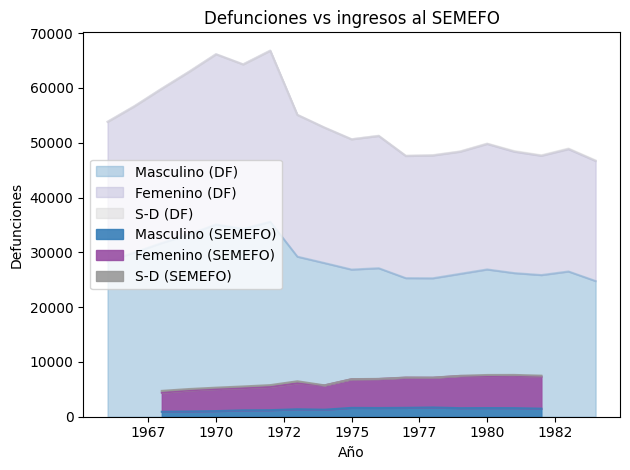

In [18]:
dic_colors = {'Masculino (SEMEFO)':'#377eb8','Femenino (SEMEFO)':'#984ea3','S-D (SEMEFO)':'#999999',
              'Masculino (DF)':'#80b1d3','Femenino (DF)':'#bebada','S-D (DF)':'#d9d9d9'}

df_año_sexo = df.pivot_table(index='Bitacora_ingresos', columns='Sexo', aggfunc='size')
df_año_sexo.index = [int(y.replace('semefo_df_bo_','')) for y in df_año_sexo.index]
df_año_sexo.columns = ['Masculino (SEMEFO)','Femenino (SEMEFO)','S-D (SEMEFO)',]
df_año_sexo

df_año_sexo_inegi = df_inegi_edad.loc[['Masculino','Femenino','S-D']].transpose().drop('Sexo')
df_año_sexo_inegi.index = [int(i) for i in df_año_sexo_inegi.index]
df_año_sexo_inegi.columns = ['Masculino (DF)','Femenino (DF)','S-D (DF)']
df_año_sexo_inegi

# Create the figure and axes object
fig, ax = plt.subplots()

# Plot the first area plot
df_año_sexo_inegi.plot.area(ax=ax, alpha=0.5, color=dic_colors)

# Plot the second area plot on the same axes
df_año_sexo.plot.area(ax=ax, alpha=0.9, color=dic_colors)

# Add labels and title
ax.set_xlabel('Año')
ax.set_ylabel('Defunciones')
ax.set_title('Defunciones vs ingresos al SEMEFO')

# Display the legend
ax.legend()
ax.legend(loc='center left')
ax.set_xticklabels([int(x) for x in ax.get_xticks()]) # Remove negative sign from tick labels
# Plotting
plt.tight_layout()
plt.show()

### Distribución de edad

Picos en edades terminadas en 0 o 5

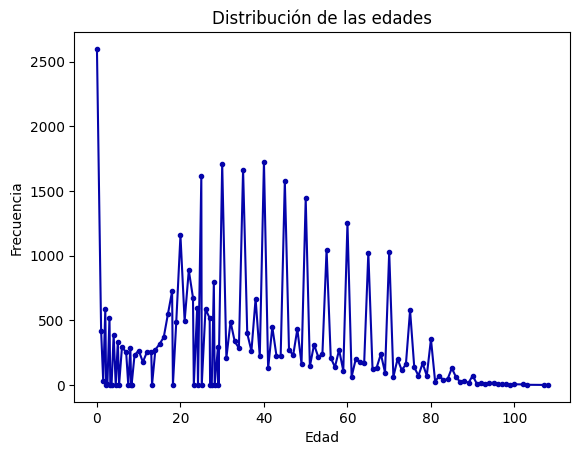

In [19]:
edad_freq = df['Edad_estandar'].value_counts().sort_index()
edad_freq

edad_freq.plot(style='.-', title="Distribución de las edades",
               xlabel='Edad', ylabel='Frecuencia', color='#0504aa'
              )
plt.show()

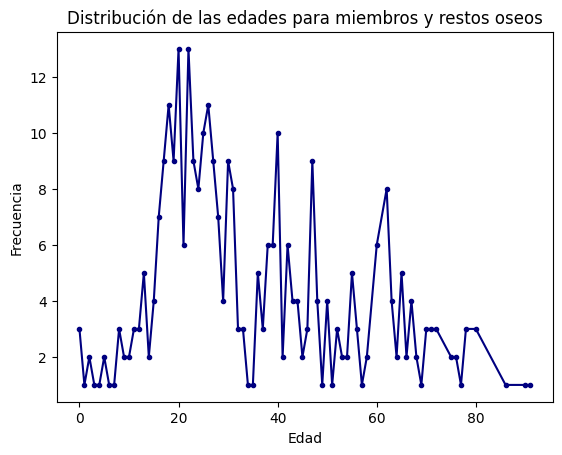

In [20]:
edad_freq = df.loc[df['Tipo_restos'].isin(['Miembros','Restos óseos']),'Edad_estandar'].value_counts().sort_index()
edad_freq

edad_freq.plot(style='.-', title="Distribución de las edades para miembros y restos oseos",
               xlabel='Edad', ylabel='Frecuencia', color='navy'
              )
plt.show()

### Edad vs sexo

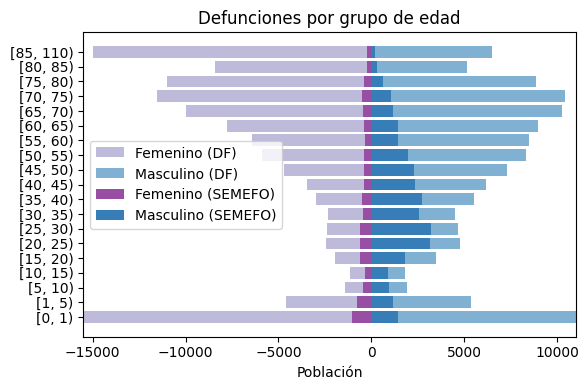

In [21]:
# Calcular frecuencia por grupo de edad y sexo
edad_sexo = df[~df['Tipo_restos'].isin(['Miembros','Restos óseos'])] \
                .pivot_table(index='Edad_grupo',columns='Sexo',values='Edad_estandar',aggfunc='count')
#display(edad_sexo)

años_edad = ['1974','1975','1976','1977','1978','1979']
index_edad = ['[0.0, 1.0)', '[1.0, 5.0)', '[5.0, 10.0)', '[10.0, 15.0)', '[15.0, 20.0)', '[20.0, 25.0)', '[25.0, 30.0)', 
              '[30.0, 35.0)', '[35.0, 40.0)', '[40.0, 45.0)', '[45.0, 50.0)', '[50.0, 55.0)', '[55.0, 60.0)', 
              '[60.0, 65.0)', '[65.0, 70.0)', '[70.0, 75.0)', '[75.0, 80.0)', '[80.0, 85.0)', '[85.0, 110.0)']
data = df_inegi_edad.loc[index_edad,['Sexo']+años_edad]
data['Freq']= data[años_edad].sum(axis=1)
data = data.reset_index().pivot(index='Edad_grupo', columns='Sexo', values='Freq').fillna(0)
data = data.loc[index_edad]
#display(data)

dic_colors = {'Masculino (SEMEFO)':'#377eb8','Femenino (SEMEFO)':'#984ea3','S-D (SEMEFO)':'#999999',
              'Masculino (DF)':'#80b1d3','Femenino (DF)':'#bebada','S-D (DF)':'#d9d9d9'}

# Set position for each age group
y = range(len(edad_sexo)) 
# Plotting
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(y, [-val for val in data['Femenino']], color='#bebada', label='Femenino (DF)') # Plot female bars (negative)
ax.barh(y, data['Masculino'], color='#80b1d3', label='Masculino (DF)') # Plot male bars (positive)
ax.barh(y, [-val for val in edad_sexo['Femenino']], color='#984ea3', label='Femenino (SEMEFO)') # Plot female bars (negative)
ax.barh(y, edad_sexo['Masculino'], color='#377eb8', label='Masculino (SEMEFO)') # Plot male bars (positive)
# Y-axis label and formatting
plt.xlim( -15500, 11000 )
ax.set_yticks(y) # Set age groups as y-ticks (on horizontal axis)
ax.set_yticklabels(edad_sexo.index)
# X-axis label and formatting
ax.set_xlabel('Población')
ax.set_title('Defunciones por grupo de edad')
ax.legend(loc='center left')
# Plotting
plt.tight_layout()
plt.show()

## Fecha
'Fecha_transcrito', 
'Fecha_estandar', 
'Fecha_año', 
'Fecha_mes',
'Fecha_diasemana',

### Ingresos anuales y diarios

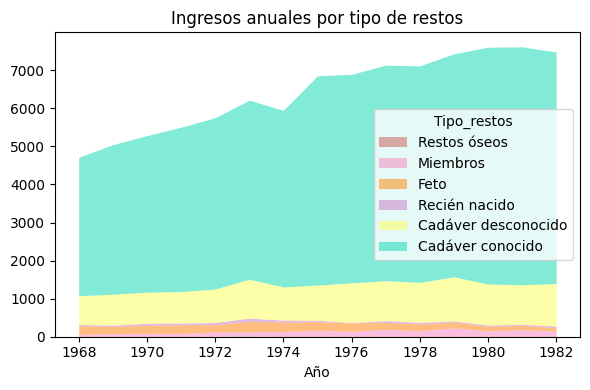

In [22]:
df_año_tipo = df.pivot_table(index='Fecha_año', columns='Tipo_restos', aggfunc='size')
df_año_tipo = df_año_tipo[df['Tipo_restos'].cat.categories].iloc[:, ::-1]
#display( df_año_tipo )

fig, ax = plt.subplots(figsize=(6, 4))
df_año_tipo.plot.area(ax=ax, color=dic_color, linewidth=0, alpha=0.5,)
ax.set_xlabel('Año')
ax.set_title('Ingresos anuales por tipo de restos')
ax.set_xticklabels([x.get_text().replace('.0','') for x in ax.get_xticklabels()]) # Remove negative sign from tick labels
plt.tight_layout()
plt.show()

**Ingresos diaros de toda la población**

En total, del 1968-01-01 al 1982-12-31 hay 5479 días
* Todos los días hubo ingresos
* Mediana de 17 ingresos diarios
* Min 2 ingresos, max 46 ingresos en un día

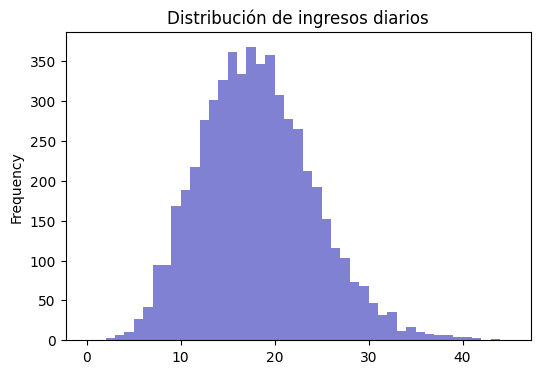

In [23]:
display()

fig, ax = plt.subplots(figsize=(6, 4))
df['Fecha_estandar'].value_counts().plot.hist(ax=ax, color=dic_color['Poblacion'], bins=range(46), alpha=0.5,
                      title='Distribución de ingresos diarios')
plt.show()

**Por tipo de restos**

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,Fecha_estandar
count,5479.000000,4844.000000,548.000000,2077.000000,1526.000000,39.000000,5479.000000
mean,13.977003,2.980388,1.153285,1.366875,1.344692,1.205128,17.628582
std,5.212342,1.805487,0.446649,0.669469,0.695980,0.570295,6.061013
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000
25%,10.000000,2.000000,1.000000,1.000000,1.000000,1.000000,13.000000
50%,14.000000,3.000000,1.000000,1.000000,1.000000,1.000000,17.000000
75%,17.000000,4.000000,1.000000,2.000000,2.000000,1.000000,21.000000
max,36.000000,18.000000,5.000000,6.000000,9.000000,3.000000,46.000000


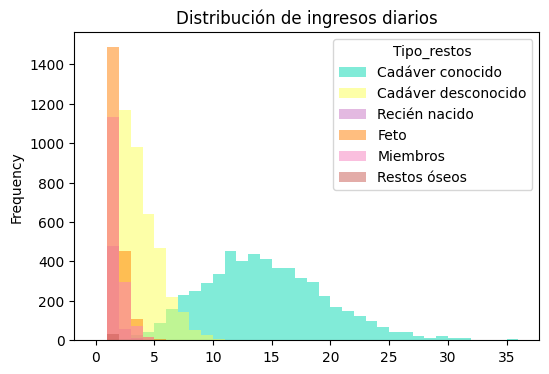

In [24]:
ing_diarios = df.pivot_table(index='Fecha_estandar', columns='Tipo_restos', aggfunc='size').sort_index().replace(0,nan)
display(pd.concat( [ing_diarios.describe(),df['Fecha_estandar'].value_counts().describe()], axis=1 ))

fig, ax = plt.subplots(figsize=(6, 4))
ing_diarios.plot.hist(ax=ax, color=dic_color, bins=range(37), alpha=0.5,
                      title='Distribución de ingresos diarios')
plt.show()

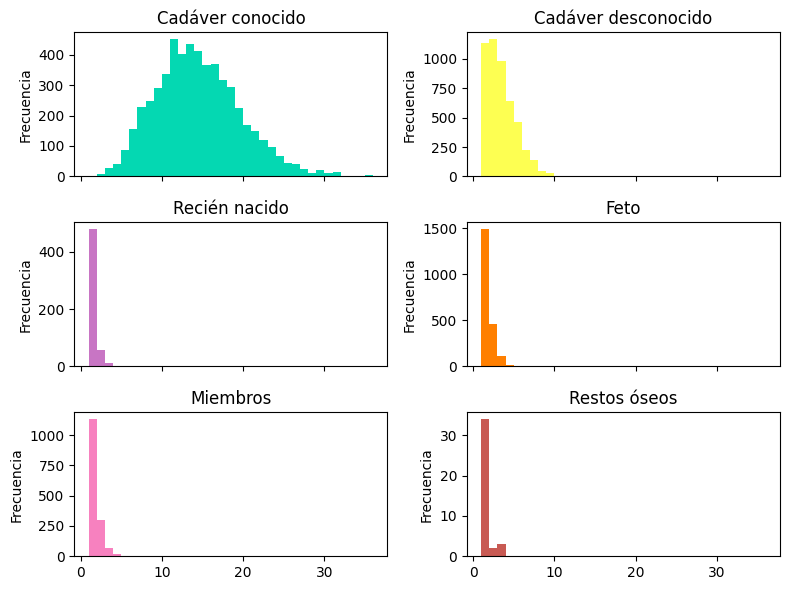

In [25]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 6), sharex=True)
axes = axes.flatten()

for ax,col in zip(axes,ing_diarios.columns):
    ing_diarios[col].plot.hist(ax=ax, color=dic_color[col], bins=range(1,37),
                               ylabel='Frecuencia', title=col
                              )
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

### Periodicidad entre años y semana



**Mediana de ingresos semanales**

In [60]:
ingresos_semanales = df.pivot_table(index='Fecha_semana', columns='Fecha_año', aggfunc='size').sort_index()
ingresos_semanales.median()

Fecha_año
1968.0     90.0
1969.0     94.0
1970.0     99.0
1971.0    102.0
1972.0    110.0
1973.0    117.0
1974.0    114.0
1975.0    132.0
1976.0    130.0
1977.0    134.0
1978.0    136.0
1979.0    142.0
1980.0    144.0
1981.0    146.0
1982.0    143.0
dtype: float64

* Incremento en ingresos en diciembre y primera de enero

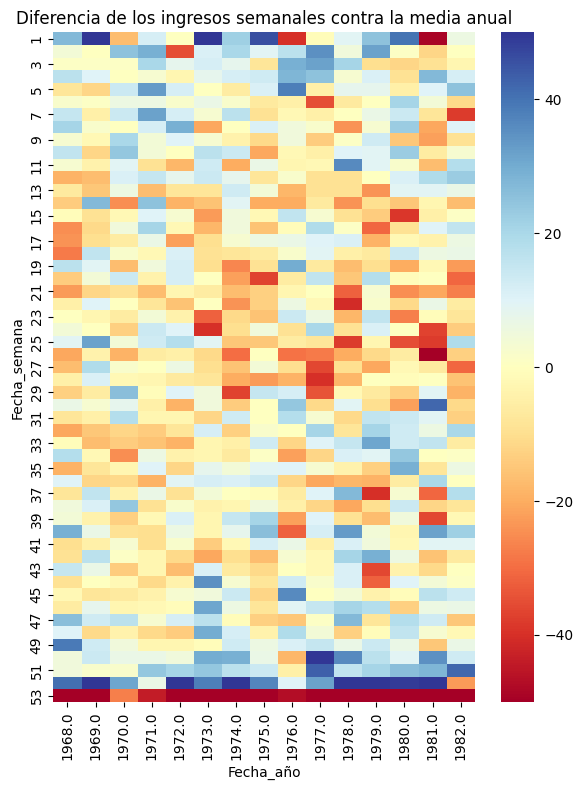

In [71]:
fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(ax=ax, data=ingresos_semanales-ingresos_semanales.median(), vmin=-50, vmax=50, cmap='RdYlBu', )
plt.title('Diferencia de los ingresos semanales contra la media anual')
plt.tight_layout()
plt.show()

In [31]:
ingresos_semanales.median()

Fecha_año
1968.0     90.0
1969.0     94.0
1970.0     99.0
1971.0    102.0
1972.0    110.0
1973.0    117.0
1974.0    114.0
1975.0    132.0
1976.0    130.0
1977.0    134.0
1978.0    136.0
1979.0    142.0
1980.0    144.0
1981.0    146.0
1982.0    143.0
dtype: float64

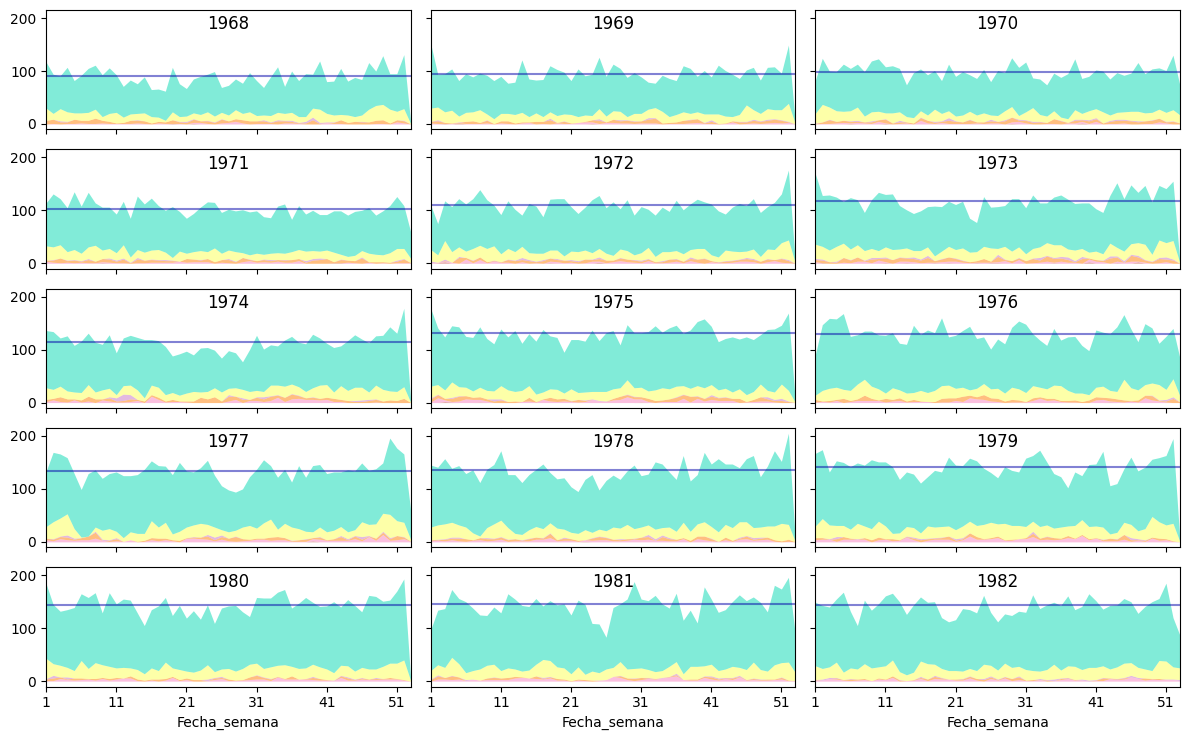

In [28]:
ncols = 3
fig, axes = plt.subplots(nrows=round(df['Fecha_año'].nunique()/ncols), ncols=ncols, 
                         figsize=(12,df['Fecha_año'].nunique()*1.5/ncols), 
                         sharex=True, sharey=True, )
for ax,año in zip(axes.flatten(),df['Fecha_año'].sort_values().dropna().unique()):
    data = df.loc[df['Fecha_año']==año,['Fecha_semana','Tipo_restos']]
    mediana_semanal = data.groupby('Fecha_semana').size().median()
    data = data.pivot_table(index='Fecha_semana',columns='Tipo_restos',aggfunc='size').iloc[:, ::-1]
    data.plot.area(ax=ax, color=dic_color, linewidth=0, alpha=0.5)
    ax.axhline(y=mediana_semanal, color=dic_color['Poblacion'], alpha=0.5)
    ax.margins(x=0)
    ax.set_title(int(año), y=1.0, pad=-14)
    ax.get_legend().remove()
plt.tight_layout()
plt.show()

### Ingresos fuera de año

## Proceso administrativo
'Numero_progresivo_transcrito', 
'Numero_acta_transcrito', 
'Expediente_SEMEFO_transcrito',
'Bitacora_ingresos', 
'Foja_transcrito', 
'Observaciones'

## Nombre
'Nombre_completo_transcrito',
'Primer_apellido', 
'Segundo_apellido', 
'Nombres_propios',

## Diagnostico
'Diagnostico_transcrito', 
'Diagnostico_estandar',
'Diagnostico_extendido', 
'Diagnostico_clasificacion',

## Procedencia
'Procedencia_transcrito', 
'Procedencia_estandar',
'Procedencia_extendido', 
'Procedencia_alcaldia',
       
## Conocido_desconocido
'Conocido_desconocido',

tabla por grupo de edad y sexo de principales causas de muerte